# 🔬 Pipeline Pengujian 100% Computer Vision Klasik (Tanpa Deep Learning)

Seluruh rangkaian tahapan murni menggunakan pemrosesan citra digital tradisional:
1. **Deteksi Wajah (ROI)** $\rightarrow$ Haar Cascade (Viola-Jones)
2. **Pengecekan Liveness (Anti-Spoofing)** $\rightarrow$ Multi-Color Space (Analisis Deviasi HSV Saturation & YCrCb Chrominance)
3. **Prapemrosesan Tekstur** $\rightarrow$ Grayscale + EqualizeHist
4. **Ekstraksi Ciri Tekstur** $\rightarrow$ Local Binary Pattern (LBP 2D Map)
5. **Klasifikasi Identitas** $\rightarrow$ Vektor Histogram 16.384D (Chi-Square $\le 25.0$ & Cosine Sim $\ge 0.5$)

- **Cell 1**: Inisialisasi library, Haar Cascade, & Database LBPH
- **Cell 2**: Uji dengan memilih file foto (Dialog Windows)
- **Cell 3**: Uji langsung dari webcam laptop

In [1]:
# Cell 1: Setup Library & Database (100% Computer Vision Klasik)
import json
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from core.engine import _extract_lbp, _resize_for_detection, _check_cv_liveness

# 1. Detektor Wajah Haar Cascade (Fallback otomatis ke YuNet jika di OpenCV 5.x)
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml") if hasattr(cv2, "CascadeClassifier") else None

# 2. Database Prototype LBPH
DB_PATH = Path("api_data/faces_lbph.json")
lbph_db = json.loads(DB_PATH.read_text(encoding="utf-8")) if DB_PATH.exists() else {}

det_info = "Haar Cascade" if (face_cascade and not face_cascade.empty()) else "YuNet (Fallback)"
print(f"✅ Setup siap!")
print(f"Detektor Wajah: {det_info}")
print("Anti-Spoofing: Multi-Color Space (HSV Saturation + YCrCb Chrominance)")
print(f"Database aktif ({len(lbph_db)} profil): {list(lbph_db.keys())}")

✅ Setup siap!
Detektor Wajah: Haar Cascade
Anti-Spoofing: Multi-Color Space (HSV Saturation + YCrCb Chrominance)
Database aktif (3 profil): ['Faza', 'Raffin', 'Rafi']


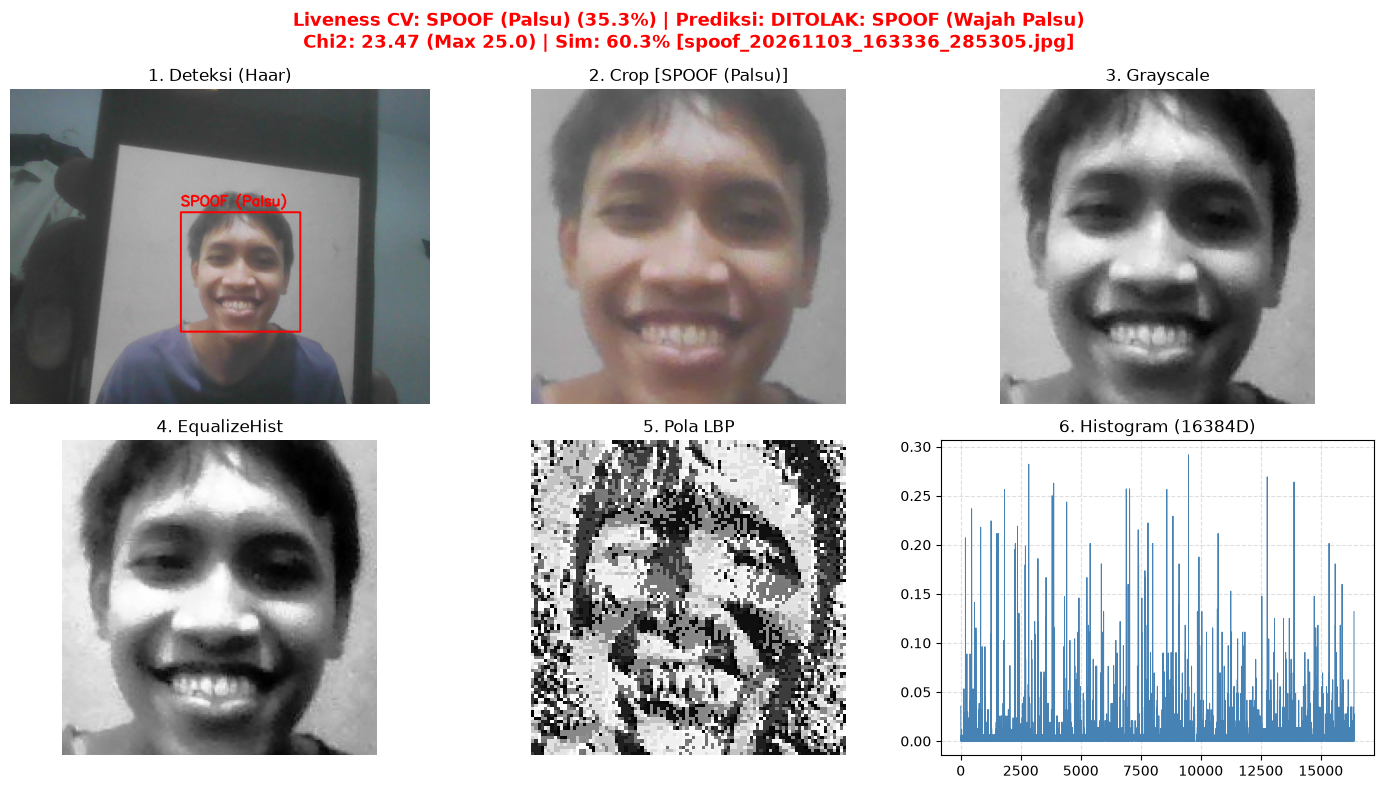

File: spoof_20261103_163336_285305.jpg
Liveness Multi-Color: SPOOF (Palsu) (Skor: 35.3%, Variansi Warna: 42.67)
⛔ AKSES DITOLAK: Wajah terdeteksi sebagai foto/layar gadget (Spoof)!


In [4]:
# Cell 2: UJI DENGAN PILIH FILE FOTO (Deteksi + Liveness Multi-Color + LBPH)
from tkinter import Tk, filedialog

# 1. Buka File Picker Windows
root = Tk(); root.withdraw(); root.attributes("-topmost", True)
file_path = filedialog.askopenfilename(title="Pilih Foto Wajah untuk Diuji", filetypes=[("File Gambar", "*.jpg *.png *.jpeg *.bmp")])
root.destroy()

if not file_path:
    print("Batal memilih file.")
else:
    # 2. Baca & Normalisasi Resolusi Citra
    frame = cv2.imread(file_path)
    frame = _resize_for_detection(frame, max_dim=1280)
    gray_full = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # 3. Deteksi Wajah (Haar Cascade / YuNet Fallback)
    if face_cascade and not face_cascade.empty():
        faces = face_cascade.detectMultiScale(gray_full, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
        bx, by, bw, bh = max(faces, key=lambda f: f[2] * f[3]) if len(faces) > 0 else (0, 0, 0, 0)
        det_name = "Haar"
    else:
        from core.detector import Detector
        acc = [d for d in Detector("face_detection_yunet_2023mar.onnx", min_score=0.5).detect_detailed(frame) if d.get("accepted")]
        bx, by, bw, bh = (int(acc[0]["x"]), int(acc[0]["y"]), int(acc[0]["w"]), int(acc[0]["h"])) if acc else (0, 0, 0, 0)
        det_name = "YuNet"

    if bw == 0:
        print(f"❌ Tidak ada wajah terdeteksi pada {Path(file_path).name}.")
    else:
        bx, by = max(0, bx), max(0, by)
        face_crop = frame[by:by+bh, bx:bx+bw]

        # 4. Pengecekan Liveness Multi-Color Space (HSV Saturation & YCrCb Chrominance)
        is_real, liveness_score, c_var = _check_cv_liveness(face_crop)
        liveness_label = "REAL (Asli)" if is_real else "SPOOF (Palsu)"

        # 5. Prapemrosesan Grayscale, EqualizeHist & Ekstraksi LBP
        gray_crop = gray_full[by:by+bh, bx:bx+bw]
        equalized = cv2.equalizeHist(gray_crop)
        vec, lbp_img = _extract_lbp(equalized, return_image=True)

        # 6. Pencocokan Jarak Chi-Square & Cosine Similarity
        candidates = []
        vec_norm = vec / (np.linalg.norm(vec) + 1e-7)
        for name, data in lbph_db.items():
            proto = np.asarray(data["histogram"], dtype=np.float32)
            sim = float(np.dot(vec_norm, proto / (np.linalg.norm(proto) + 1e-7)))
            chi2 = float(0.5 * np.sum(((vec - proto) ** 2) / (vec + proto + 1e-7)))
            candidates.append((name, chi2, sim))

        candidates.sort(key=lambda x: x[1])
        top1_name, top1_dist, top1_sim = candidates[0]

        # 7. Pengambilan Keputusan Akhir
        if not is_real:
            pred = "DITOLAK: SPOOF (Wajah Palsu)"
            title_color = "red"
            box_color = (0, 0, 255) # Merah (BGR)
        else:
            is_match = bool(top1_dist <= 25.0 and top1_sim >= 0.5)
            pred = f"{top1_name} (REAL)" if is_match else "Unknown (REAL)"
            title_color = "green" if is_match else "darkorange"
            box_color = (0, 255, 0) if is_match else (0, 165, 255)

        # 8. Visualisasi Subplot 2x3
        fig, ax = plt.subplots(2, 3, figsize=(14, 8))
        fig.suptitle(f"Liveness CV: {liveness_label} ({liveness_score*100:.1f}%) | Prediksi: {pred}\nChi2: {top1_dist:.2f} (Max 25.0) | Sim: {top1_sim*100:.1f}% [{Path(file_path).name}]",
                     fontsize=13, fontweight="bold", color=title_color)

        vis = frame.copy()
        cv2.rectangle(vis, (bx, by), (bx + bw, by + bh), box_color, 2)
        cv2.putText(vis, f"{liveness_label}", (bx, max(20, by - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, box_color, 2)

        ax[0, 0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax[0, 0].set_title(f"1. Deteksi ({det_name})")
        ax[0, 1].imshow(cv2.cvtColor(face_crop, cv2.COLOR_BGR2RGB)); ax[0, 1].set_title(f"2. Crop [{liveness_label}]")
        ax[0, 2].imshow(gray_crop, cmap="gray"); ax[0, 2].set_title("3. Grayscale")
        ax[1, 0].imshow(equalized, cmap="gray"); ax[1, 0].set_title("4. EqualizeHist")
        ax[1, 1].imshow(lbp_img, cmap="gray"); ax[1, 1].set_title("5. Pola LBP")
        ax[1, 2].plot(vec, color="steelblue", lw=0.7); ax[1, 2].set_title(f"6. Histogram ({len(vec)}D)")
        ax[1, 2].grid(True, linestyle="--", alpha=0.4)
        for a in ax.flat[:5]: a.axis("off")
        plt.tight_layout(); plt.show()

        print(f"File: {Path(file_path).name}")
        print(f"Liveness Multi-Color: {liveness_label} (Skor: {liveness_score*100:.1f}%, Variansi Warna: {c_var})")
        if not is_real:
            print("⛔ AKSES DITOLAK: Wajah terdeteksi sebagai foto/layar gadget (Spoof)!")
        else:
            print("Hasil Evaluasi Jarak LBPH (Threshold Chi2 <= 25.0, Sim >= 50%):")
            for name, c2, sim in candidates:
                st = "MATCH" if name == top1_name and is_match else "-"
                print(f"  [{st:5s}] {name:10s} -> Chi2: {c2:6.2f}, Sim: {sim*100:5.1f}%")

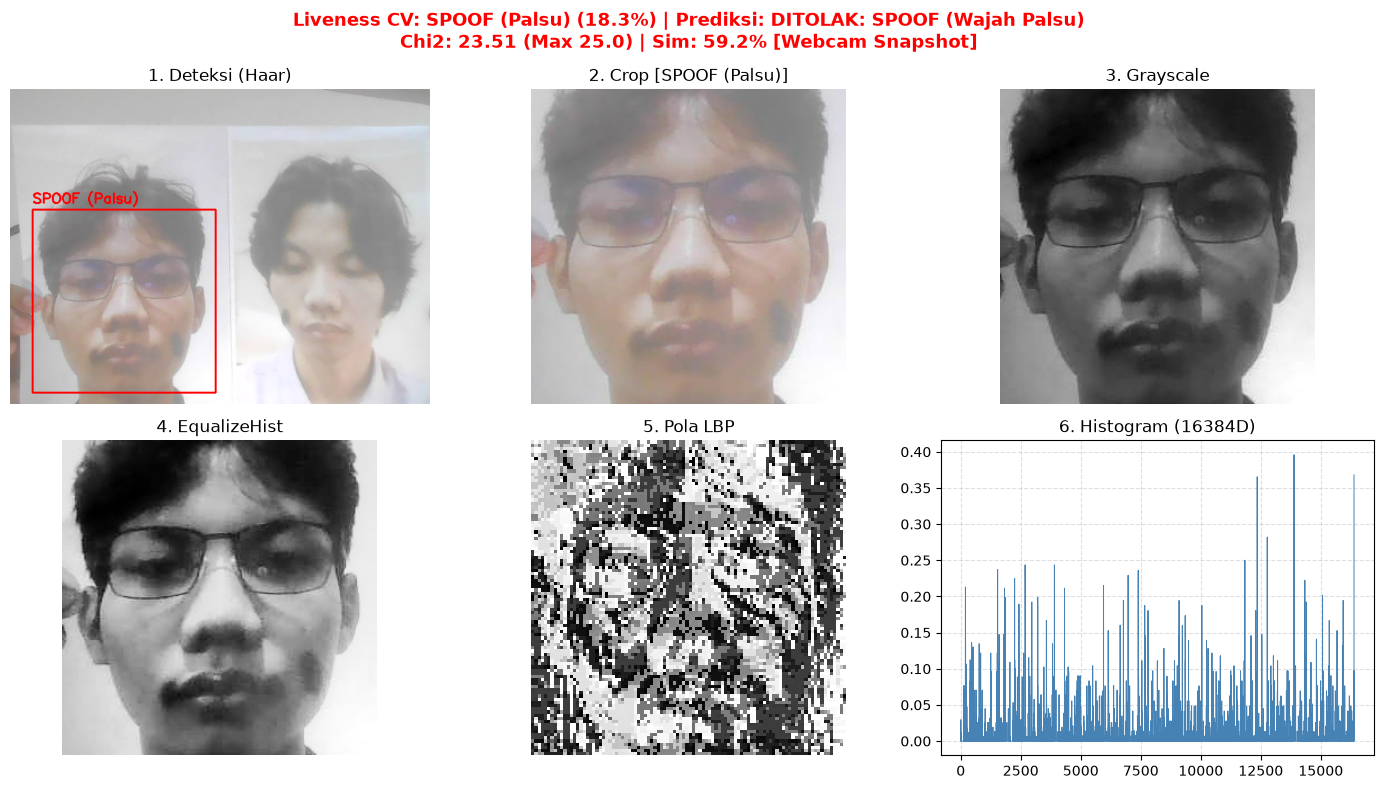

Sumber: Webcam Snapshot
Liveness Multi-Color: SPOOF (Palsu) (Skor: 18.3%, Variansi Warna: 34.13)
⛔ AKSES DITOLAK: Wajah terdeteksi sebagai foto/layar gadget (Spoof)!


In [14]:
# Cell 3: UJI DENGAN WEBCAM LAPTOP (Deteksi + Liveness Multi-Color + LBPH)

# 1. Ambil 1 Frame dari Webcam
cap = cv2.VideoCapture(0)
for _ in range(5): cap.read() # hangatkan sensor kamera
ret, frame = cap.read(); cap.release()

if not ret or frame is None:
    print("❌ Gagal mengambil gambar dari webcam. Pastikan kamera tidak dipakai aplikasi lain.")
else:
    # 2. Resize & Normalisasi Resolusi Citra
    frame = _resize_for_detection(frame, max_dim=1280)
    gray_full = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # 3. Deteksi Wajah (Haar Cascade / YuNet Fallback)
    if face_cascade and not face_cascade.empty():
        faces = face_cascade.detectMultiScale(gray_full, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
        bx, by, bw, bh = max(faces, key=lambda f: f[2] * f[3]) if len(faces) > 0 else (0, 0, 0, 0)
        det_name = "Haar"
    else:
        from core.detector import Detector
        acc = [d for d in Detector("face_detection_yunet_2023mar.onnx", min_score=0.5).detect_detailed(frame) if d.get("accepted")]
        bx, by, bw, bh = (int(acc[0]["x"]), int(acc[0]["y"]), int(acc[0]["w"]), int(acc[0]["h"])) if acc else (0, 0, 0, 0)
        det_name = "YuNet"

    if bw == 0:
        print("❌ Tidak ada wajah terdeteksi di depan webcam.")
    else:
        bx, by = max(0, bx), max(0, by)
        face_crop = frame[by:by+bh, bx:bx+bw]

        # 4. Pengecekan Liveness Multi-Color Space (HSV Saturation & YCrCb Chrominance)
        is_real, liveness_score, c_var = _check_cv_liveness(face_crop)
        liveness_label = "REAL (Asli)" if is_real else "SPOOF (Palsu)"

        # 5. Prapemrosesan Grayscale, EqualizeHist & Ekstraksi LBP
        gray_crop = gray_full[by:by+bh, bx:bx+bw]
        equalized = cv2.equalizeHist(gray_crop)
        vec, lbp_img = _extract_lbp(equalized, return_image=True)

        # 6. Pencocokan Jarak Chi-Square & Cosine Similarity
        candidates = []
        vec_norm = vec / (np.linalg.norm(vec) + 1e-7)
        for name, data in lbph_db.items():
            proto = np.asarray(data["histogram"], dtype=np.float32)
            sim = float(np.dot(vec_norm, proto / (np.linalg.norm(proto) + 1e-7)))
            chi2 = float(0.5 * np.sum(((vec - proto) ** 2) / (vec + proto + 1e-7)))
            candidates.append((name, chi2, sim))

        candidates.sort(key=lambda x: x[1])
        top1_name, top1_dist, top1_sim = candidates[0]

        # 7. Pengambilan Keputusan Akhir
        if not is_real:
            pred = "DITOLAK: SPOOF (Wajah Palsu)"
            title_color = "red"
            box_color = (0, 0, 255) # Merah (BGR)
        else:
            is_match = bool(top1_dist <= 25.0 and top1_sim >= 0.5)
            pred = f"{top1_name} (REAL)" if is_match else "Unknown (REAL)"
            title_color = "green" if is_match else "darkorange"
            box_color = (0, 255, 0) if is_match else (0, 165, 255)

        # 8. Visualisasi Subplot 2x3
        fig, ax = plt.subplots(2, 3, figsize=(14, 8))
        fig.suptitle(f"Liveness CV: {liveness_label} ({liveness_score*100:.1f}%) | Prediksi: {pred}\nChi2: {top1_dist:.2f} (Max 25.0) | Sim: {top1_sim*100:.1f}% [Webcam Snapshot]",
                     fontsize=13, fontweight="bold", color=title_color)

        vis = frame.copy()
        cv2.rectangle(vis, (bx, by), (bx + bw, by + bh), box_color, 2)
        cv2.putText(vis, f"{liveness_label}", (bx, max(20, by - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, box_color, 2)

        ax[0, 0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax[0, 0].set_title(f"1. Deteksi ({det_name})")
        ax[0, 1].imshow(cv2.cvtColor(face_crop, cv2.COLOR_BGR2RGB)); ax[0, 1].set_title(f"2. Crop [{liveness_label}]")
        ax[0, 2].imshow(gray_crop, cmap="gray"); ax[0, 2].set_title("3. Grayscale")
        ax[1, 0].imshow(equalized, cmap="gray"); ax[1, 0].set_title("4. EqualizeHist")
        ax[1, 1].imshow(lbp_img, cmap="gray"); ax[1, 1].set_title("5. Pola LBP")
        ax[1, 2].plot(vec, color="steelblue", lw=0.7); ax[1, 2].set_title(f"6. Histogram ({len(vec)}D)")
        ax[1, 2].grid(True, linestyle="--", alpha=0.4)
        for a in ax.flat[:5]: a.axis("off")
        plt.tight_layout(); plt.show()

        print("Sumber: Webcam Snapshot")
        print(f"Liveness Multi-Color: {liveness_label} (Skor: {liveness_score*100:.1f}%, Variansi Warna: {c_var})")
        if not is_real:
            print("⛔ AKSES DITOLAK: Wajah terdeteksi sebagai foto/layar gadget (Spoof)!")
        else:
            print("Hasil Evaluasi Jarak LBPH (Threshold Chi2 <= 25.0, Sim >= 50%):")
            for name, c2, sim in candidates:
                st = "MATCH" if name == top1_name and is_match else "-"
                print(f"  [{st:5s}] {name:10s} -> Chi2: {c2:6.2f}, Sim: {sim*100:5.1f}%")